# 2. Can the signal be traded on its own?

**Policy.** When the forecast's magnitude exceeds $\theta = 0.415$ bp (the 90% quantile of $|f|$ on the validation days), we send a market order of about 100 USDT in the forecast's direction. We hold for 5 s and then close with market orders, retried every second until flat. Orders that would take more than 1% of the visible top-5 depth are refused, and no positions are opened within 60 s of a whole hour (funding times).

**Replay.** Orders are filled by walking the historical top-50 book (`orderflow/taker.py`) after an order delay $d_o$, using features visible at $t - d$. Our orders do not move the book; this is the main limitation (see the end). For each day we record the fee-free P&L $\Pi_t$ and the traded value $N_t$. Net P&L at a per-side fee $\phi$ is $\Pi - \phi N$, so the **break-even fee** is
$$f^* = 10^4\,\frac{\sum_t \Pi_t}{\sum_t N_t}\ \text{bp per side}.$$
Bybit's published taker fee is 5.5 bp per side.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':      # paths below are relative to the repository root
    os.chdir('..')
sys.path.insert(0, os.getcwd())
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from orderflow import stats

def read_csv(name):
    with open('results/' + name) as f:
        return list(csv.DictReader(f))

S = json.load(open('results/summary.json'))           # every number quoted in the README
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

days = read_csv('sealed_test_days.csv')
U = 100_000                        # price x size units per USDT
print('latency (data/order)  round trips   traded (USDT)   f* (bp)   net at 1 bp   net at 5.5 bp (USDT)')
fstar = {}
for lat in ('0_0', '100_100', '500_500', '1000_1000'):
    pi = sum(int(r[f'lat_{lat}_pi']) for r in days)
    n = sum(int(r[f'lat_{lat}_n']) for r in days)
    trips = sum(int(r[f'lat_{lat}_trips']) for r in days)
    fstar[lat] = 1e4 * pi / n
    print(f"{lat.replace('_', '/'):>10s} ms        {trips:7d}   {n / U:14,.0f}   {fstar[lat]:7.3f}   {(pi - 1e-4 * n) / U:10,.0f}   {(pi - 5.5e-4 * n) / U:10,.0f}")

res = stats.primary([float(r['D1']) for r in days], [float(r['D2']) for r in days],
                    [int(r['lat_100_100_pi']) for r in days], [int(r['lat_100_100_n']) for r in days])
Q3 = res['quantities']['Q3']
print(f"\nf* at 100/100 ms = {Q3['estimate_bp']:.3f} bp; bootstrap intervals (1/2/5-day blocks):",
      [[round(x, 3) for x in res['bootstrap'][b]['Q3']] for b in ('1', '2', '5')])
print('vs 0:', Q3['vs_zero'], '| vs 5.5 bp:', Q3['vs_5.5bp'], '| reading:', Q3['reading'])
assert Q3['estimate_bp'] == S['trade_alone']['break_even_fee']['estimate_bp']

latency (data/order)  round trips   traded (USDT)   f* (bp)   net at 1 bp   net at 5.5 bp (USDT)
       0/0 ms          56901       10,524,532     0.327         -708       -5,444
   100/100 ms          78589       14,544,798     0.162       -1,219       -7,764
   500/500 ms          96749       17,932,669     0.056       -1,692       -9,762
 1000/1000 ms          90794       16,836,859     0.012       -1,664       -9,241

f* at 100/100 ms = 0.162 bp; bootstrap intervals (1/2/5-day blocks): [[0.139, 0.185], [0.133, 0.189], [0.126, 0.189]]
vs 0: robustly_positive | vs 5.5 bp: robustly_at_or_below | reading: positive_fee_budget_below_5.5bp


The policy has a fee-free edge, robustly above zero, but the break-even fee of 0.16 bp is about 34 times smaller than the 5.5 bp taker fee. The edge also shrinks quickly with latency. The cost-aware version of the policy, which trades only when $|f|$ exceeds the spread plus fees, never traded on the validation days, so it was frozen as "do not trade".

## Where does the edge go?

We decompose every one of the 78,589 round trips at 100/100 ms. With side $s = \pm1$, the mid at decision $M_d$, at entry arrival $M_a$ and at the completing exit $M_x$, all in bp of $M_d$:

- $H_d = s(M_x - M_d)$: the mid move the forecast was trying to catch;
- $A = s(M_a - M_d)$: the part that happened during the 100 ms before our order arrived;
- $C_{in}, C_{out}$: what crossing the spread and walking the book cost on entry and exit;
- $G = H_d - A - C_{in} - C_{out}$: the gross edge left per round trip.

These identities hold exactly, in integers, for every trade.

mid move from decision to exit, H_d     0.610 bp   95% [0.574, 0.644]
lost to the 100 ms arrival delay, A     0.276 bp   95% [0.252, 0.300]
entry crossing cost, C_in               0.006 bp   95% [0.006, 0.006]
exit crossing cost, C_out               0.006 bp   95% [0.006, 0.006]
gross edge left, G                      0.323 bp   95% [0.282, 0.359]
mean predicted move |f|: 0.443 bp; round-trip taker fee: 11 bp



fixed cohort of trades, f* by order delay: {'0 ms': 0.202, '100 ms': 0.162, '500 ms': 0.116, '1000 ms': 0.074}


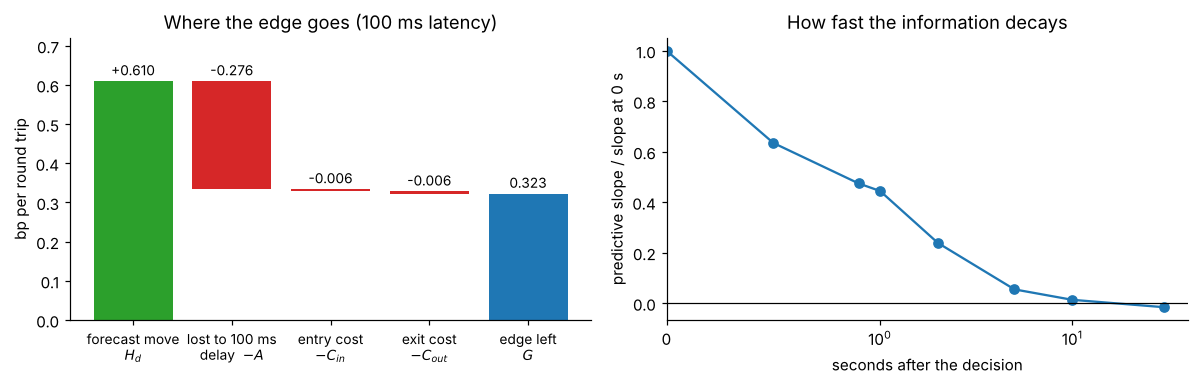

In [2]:
W = S['where_edge_goes']
dec, ci = W['decomposition_bp'], W['decomposition_ci95']
for k, name in (('Hd', 'mid move from decision to exit, H_d'), ('A', 'lost to the 100 ms arrival delay, A'),
                ('Ci', 'entry crossing cost, C_in'), ('Co', 'exit crossing cost, C_out'), ('G', 'gross edge left, G')):
    print(f"{name:38s} {dec[k]:6.3f} bp   95% [{ci[k][0]:.3f}, {ci[k][1]:.3f}]")
print(f"mean predicted move |f|: {dec['abs_f']:.3f} bp; round-trip taker fee: 11 bp")

steps = [('forecast move\n$H_d$', dec['Hd']), ('lost to 100 ms\ndelay  $-A$', -dec['A']),
         ('entry cost\n$-C_{in}$', -dec['Ci']), ('exit cost\n$-C_{out}$', -dec['Co'])]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
level = 0
for i, (name, v) in enumerate(steps):
    ax[0].bar(i, v, bottom=level, color='tab:green' if v > 0 else 'tab:red')
    ax[0].text(i, max(level, level + v) + 0.015, f'{v:+.3f}', ha='center', fontsize=9)
    level += v
ax[0].bar(len(steps), level, color='tab:blue')
ax[0].text(len(steps), level + 0.015, f'{level:.3f}', ha='center', fontsize=9)
ax[0].set_xticks(range(5), [n for n, _ in steps] + ['edge left\n$G$'], fontsize=9)
ax[0].set_ylim(0, 0.72)
ax[0].set_ylabel('bp per round trip')
ax[0].set_title('Where the edge goes (100 ms latency)')
lags = sorted(W['decay_slope_ratio'], key=float)
ax[1].plot([float(x) for x in lags], [W['decay_slope_ratio'][x] for x in lags], 'o-')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xscale('symlog', linthresh=1)
ax[1].set_xlim(0, 40)
ax[1].set_xlabel('seconds after the decision')
ax[1].set_ylabel('predictive slope / slope at 0 s')
ax[1].set_title('How fast the information decays')
fig.tight_layout()
fig.savefig('figures/edge_decomposition.png')

print('\nfixed cohort of trades, f* by order delay:', {k + ' ms': round(v, 3) for k, v in W['fixed_cohort_break_even_bp'].items()})

Most of the forecast move is lost to latency, not to the spread: 45% disappears in the 100 ms before the order arrives, while crossing the spread and walking the book cost only about 0.012 bp per round trip, about half the quoted spread on each side, so a 100 USDT order rarely needs more than the best level of this very liquid market. Half of the predictive slope is gone after about a second and nearly all of it after 10 s.

**Longer horizons?** A slower forecast would pay the same fee for a larger move. We refitted the model at horizons of 1 to 300 s (descriptive models, not the frozen one):

In [3]:
H = S['trade_alone']['longer_horizons']
print('horizon   R2 pooled   99% quantile of |f| (bp)   round-trip cost (bp)   trades screened')
for h in sorted(H, key=int):
    v = H[h]
    print(f"{h:>5s} s    {v['r2_pooled']:.4f}            {v['abs_f_quantiles_bp']['p99']:.2f}                     {v['c_bp']['fold1']:.1f}               {v['screened']}")
print('\nfrozen reading:', S['trade_alone']['longer_horizons_reading']['reading'])
h300 = H['300']['mean_net_bp']
print(f"300 s: {H['300']['priced']} priced trades, mean net {h300['point']:.1f} bp, 95% [{h300['ci95'][0]:.1f}, {h300['ci95'][1]:.1f}]")

horizon   R2 pooled   99% quantile of |f| (bp)   round-trip cost (bp)   trades screened
    1 s    0.0438            0.25                     11.0               0
    5 s    0.0255            0.48                     11.0               0
   15 s    0.0110            0.53                     11.0               0
   60 s    0.0023            0.80                     11.0               0
  300 s    0.0006            0.83                     11.0               30

frozen reading: inconclusive
300 s: 29 priced trades, mean net -10.0 bp, 95% [-15.9, -0.5]


At every horizon even the 99th percentile of the forecast is at least 13 times smaller than the cost of a round trip, so almost no trade passes a cost screen. The few that do at 300 s lose money on average. The pre-registered reading is *inconclusive*: one of the 30 screened trades could not be priced, and our rule never counts missing evidence as "no edge".

**Conclusion.** The signal cannot be traded on its own by a taker under the fees tested. Its value lies in the first second, and most of it is gone before a 100 ms order arrives.